Importing libraries

In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score,
    roc_auc_score, average_precision_score, ConfusionMatrixDisplay,
)

RANDOM_STATE = 20
os.makedirs("processed", exist_ok=True)

Load Dataset

In [2]:
data = pd.read_csv("processed/nsw_crashes_classification.csv")

# Identifiers and leakage columns (severity / casualty counts) must never be features
DROP_COLS = ["Crash ID", "LGA code", "Degree of crash", "Degree of crash - detailed",
             "No. killed", "No. seriously injured", "No. moderately injured", "No. minor-other injured"]
data = data.drop(columns=DROP_COLS, errors="ignore")

print(data.shape)
print("Missing values:", int(data.isna().sum().sum()))
print(data["Severe_Crash"].value_counts(normalize=True).round(4))

(90857, 11)
Missing values: 0
Severe_Crash
1    0.6793
0    0.3207
Name: proportion, dtype: float64


Build features & target

In [ ]:
CAT_FEATURES = ["Weather", "Road classification (admin)", "Road surface",
                "Surface condition", "Urbanisation", "Season",
                "Speed limit"]            # speed limit as a category: its effect is not linear
NUM_FEATURES = ["Population"]
FEATURES = CAT_FEATURES + NUM_FEATURES

X = data[FEATURES]
y = data["Severe_Crash"]                  # 1 = Severe, 0 = Non-severe

# Stratified split (fixed seed): keeps the 67.93% / 32.07% class share, so the baseline matches the brief
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

# Non-severe (minority class) is the class of interest below
y_ns_train = (y_train == 0).to_numpy()
y_ns_test = (y_test == 0).to_numpy()

BASELINE_ACC = 1 - y_ns_test.mean()
PREVALENCE_NS = y_ns_test.mean()
TRIVIAL_F1_NS = 2 * PREVALENCE_NS / (1 + PREVALENCE_NS)   # F1 of "predict non-severe for everything"

print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print(f"Baseline accuracy (always Severe)     : {BASELINE_ACC:.2%}")
print(f"Non-severe prevalence (PR-AUC baseline): {PREVALENCE_NS:.2%}")
print(f"Non-severe F1 of 'always Non-severe'   : {TRIVIAL_F1_NS:.3f}")

Train: (72685, 8) | Test: (18172, 8)
Baseline accuracy (always Severe)     : 67.93%
Non-severe prevalence (PR-AUC baseline): 32.07%
Non-severe F1 of 'always Non-severe'   : 0.486


Pipelines & tuning (training data only)

In [4]:
def make_pipeline(model):
    prep = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_FEATURES),
        ("num", StandardScaler(), NUM_FEATURES),
    ])
    return Pipeline([("prep", prep), ("model", model)])


tune_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

lr_search = GridSearchCV(
    make_pipeline(LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE)),
    {"model__C": [0.01, 0.1, 1, 10]},
    cv=tune_cv, scoring="roc_auc", n_jobs=-1,
).fit(X_train, y_train)

rf_search = GridSearchCV(
    make_pipeline(RandomForestClassifier(n_estimators=150, class_weight="balanced_subsample",
                                         n_jobs=-1, random_state=RANDOM_STATE)),
    {"model__max_depth": [6, 10], "model__min_samples_leaf": [20, 100]},
    cv=tune_cv, scoring="roc_auc",
).fit(X_train, y_train)

lr_model, rf_model = lr_search.best_estimator_, rf_search.best_estimator_
print("Logistic Regression:", lr_search.best_params_)
print("Random Forest      :", rf_search.best_params_)

Logistic Regression: {'model__C': 1}
Random Forest      : {'model__max_depth': 10, 'model__min_samples_leaf': 20}


Cross-validation & threshold (training data only)

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def cross_validate_oof(model):
    # Out-of-fold P(non-severe) for every training crash + per-fold scores
    oof_ns = np.zeros(len(y_train))
    auc_scores, pr_scores = [], []
    for fit_idx, val_idx in cv.split(X_train, y_train):
        fold_model = clone(model).fit(X_train.iloc[fit_idx], y_train.iloc[fit_idx])
        p_ns = fold_model.predict_proba(X_train.iloc[val_idx])[:, 0]
        oof_ns[val_idx] = p_ns
        auc_scores.append(roc_auc_score(y_ns_train[val_idx], p_ns))
        pr_scores.append(average_precision_score(y_ns_train[val_idx], p_ns))
    return oof_ns, np.array(auc_scores), np.array(pr_scores)


def pick_threshold(y_ns, p_ns, metric):
    grid = np.linspace(0.05, 0.95, 91)
    scores = [metric(y_ns, p_ns >= t) for t in grid]
    return float(grid[int(np.argmax(scores))])


cv_rows, thresholds = [], {}
for name, model in [("Logistic Regression", lr_model), ("Random Forest", rf_model)]:
    oof_ns, aucs, prs = cross_validate_oof(model)
    # Threshold on P(non-severe), chosen from out-of-fold training predictions only
    thresholds[name] = {
        "balanced_accuracy": pick_threshold(y_ns_train, oof_ns, balanced_accuracy_score),
        "f1_non_severe": pick_threshold(y_ns_train, oof_ns, f1_score),
    }
    cv_rows.append({
        "Model": name,
        "CV ROC-AUC": f"{aucs.mean():.3f} ± {aucs.std():.3f}",
        "CV PR-AUC (non-severe)": f"{prs.mean():.3f} ± {prs.std():.3f}",
        "pr_mean": prs.mean(),
        "Threshold (balanced acc.)": thresholds[name]["balanced_accuracy"],
        "Threshold (non-severe F1)": thresholds[name]["f1_non_severe"],
    })

cv_table = pd.DataFrame(cv_rows).set_index("Model")
display(cv_table.drop(columns="pr_mean"))

,CV ROC-AUC,CV PR-AUC (non-severe),Threshold (balanced acc.),Threshold (non-severe F1)
Model,,,,
Logistic Regression,0.569 ± 0.007,0.378 ± 0.007,0.51,0.40
Random Forest,0.574 ± 0.004,0.380 ± 0.006,0.50,0.41


Test evaluation (test set used once)

In [6]:
def evaluate(name, p_ns, threshold):
    pred_ns = p_ns >= threshold
    return {
        "Model": name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_ns_test, pred_ns),
        "Precision (NS)": precision_score(y_ns_test, pred_ns, zero_division=0),
        "Recall (NS)": recall_score(y_ns_test, pred_ns),
        "F1 (NS)": f1_score(y_ns_test, pred_ns),
        "Balanced acc.": balanced_accuracy_score(y_ns_test, pred_ns),
        "ROC-AUC": roc_auc_score(y_ns_test, p_ns),
        "PR-AUC (NS)": average_precision_score(y_ns_test, p_ns),
    }


p_ns_test = {
    "Logistic Regression": lr_model.predict_proba(X_test)[:, 0],
    "Random Forest": rf_model.predict_proba(X_test)[:, 0],
}

rows = [
    evaluate("Dummy: always Severe", np.zeros(len(y_test)), 0.5),
    evaluate("Dummy: always Non-severe", np.ones(len(y_test)), 0.5),
]
for name, p_ns in p_ns_test.items():
    rows.append(evaluate(f"{name} (threshold 0.5)", p_ns, 0.5))
    rows.append(evaluate(f"{name} (threshold: balanced acc.)", p_ns, thresholds[name]["balanced_accuracy"]))
    rows.append(evaluate(f"{name} (threshold: non-severe F1)", p_ns, thresholds[name]["f1_non_severe"]))

results = pd.DataFrame(rows).set_index("Model").round(3)
print(f"Baseline accuracy: {BASELINE_ACC:.4f} | Non-severe prevalence (PR-AUC baseline): {PREVALENCE_NS:.4f} | 'Always non-severe' F1: {TRIVIAL_F1_NS:.3f}")
print("NS = non-severe (positive class)")
results

Baseline accuracy: 0.6793 | Non-severe prevalence (PR-AUC baseline): 0.3207 | 'Always non-severe' F1: 0.486
NS = non-severe (positive class)


,Threshold,Accuracy,Precision (NS),Recall (NS),F1 (NS),Balanced acc.,ROC-AUC,PR-AUC (NS)
Model,,,,,,,,
Dummy: always Severe,0.50,0.679,0.000,0.000,0.000,0.500,0.500,0.321
Dummy: always Non-severe,0.50,0.321,0.321,1.000,0.486,0.500,0.500,0.321
Logistic Regression (threshold 0.5),0.50,0.554,0.368,0.544,0.439,0.551,0.569,0.378
Logistic Regression (threshold: balanced acc.),0.51,0.568,0.372,0.502,0.427,0.551,0.569,0.378
Logistic Regression (threshold: non-severe F1),0.40,0.345,0.325,0.966,0.486,0.509,0.569,0.378
Random Forest (threshold 0.5),0.50,0.579,0.381,0.498,0.432,0.558,0.574,0.381
Random Forest (threshold: balanced acc.),0.50,0.579,0.381,0.498,0.432,0.558,0.574,0.381
Random Forest (threshold: non-severe F1),0.41,0.349,0.326,0.968,0.488,0.512,0.574,0.381


Confusion matrices

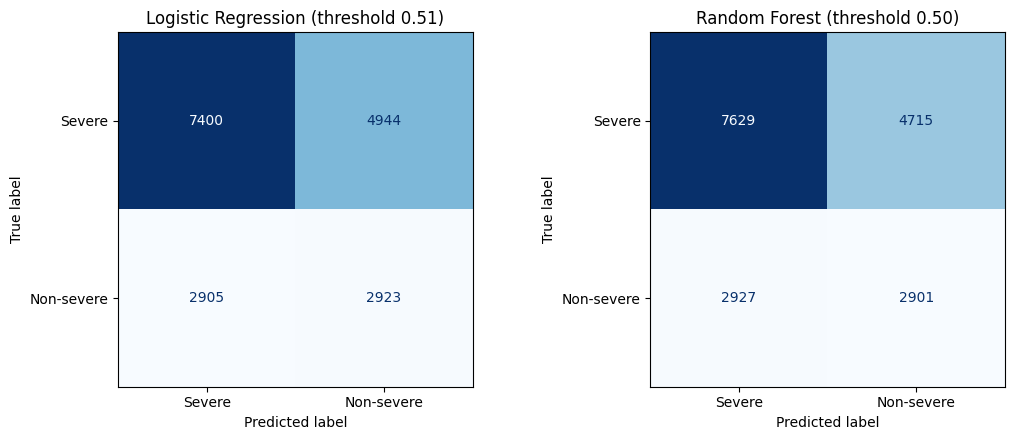

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, name in zip(axes, p_ns_test):
    thr = thresholds[name]["balanced_accuracy"]
    ConfusionMatrixDisplay.from_predictions(
        y_ns_test, p_ns_test[name] >= thr, display_labels=["Severe", "Non-severe"],
        cmap="Blues", ax=ax, colorbar=False,
    )
    ax.set_title(f"{name} (threshold {thr:.2f})")

plt.tight_layout()
plt.show()

Feature importance

In [8]:
# Logistic Regression coefficients (positive = pushes towards Severe)
names = [n.split("__", 1)[1] for n in lr_model.named_steps["prep"].get_feature_names_out()]
coef = pd.Series(lr_model.named_steps["model"].coef_[0], index=names).sort_values()
print("Towards Non-severe:"); display(coef.head(5).round(3))
print("Towards Severe:");     display(coef.tail(5).iloc[::-1].round(3))

# Permutation importance on the test set (drop in ROC-AUC when a feature is shuffled)
def perm_importance(model):
    perm = permutation_importance(model, X_test, y_test, n_repeats=10,
                                  random_state=RANDOM_STATE, scoring="roc_auc")
    return pd.DataFrame({"feature": FEATURES, "importance_mean": perm.importances_mean,
                         "importance_std": perm.importances_std}
                        ).sort_values("importance_mean", ascending=False).reset_index(drop=True)

importance_lr = perm_importance(lr_model)
importance_rf = perm_importance(rf_model)
display(importance_lr.round(4))
display(importance_rf.round(4))

Towards Non-severe:


Speed limit_110                 -0.526
Speed limit_50                  -0.336
Surface condition_Snow or ice   -0.315
Road surface_Sealed             -0.204
Speed limit_100                 -0.202
dtype: float64

Towards Severe:


Speed limit_30           0.738
Surface condition_Dry    0.270
Speed limit_20           0.230
Road surface_Unsealed    0.201
Weather_Fine             0.198
dtype: float64

,feature,importance_mean,importance_std
0,Speed limit,0.0307,0.0028
1,Surface condition,0.0079,0.0008
2,Road classification (admin),0.0065,0.0011
3,Population,0.0059,0.0012
4,Weather,0.0050,0.0013
5,Road surface,0.0030,0.0009
6,Urbanisation,0.0025,0.0008
7,Season,0.0010,0.0006


,feature,importance_mean,importance_std
0,Speed limit,0.0317,0.0024
1,Road classification (admin),0.0165,0.0019
2,Surface condition,0.0085,0.0010
3,Weather,0.0068,0.0018
4,Population,0.0052,0.0014
5,Urbanisation,0.0043,0.0014
6,Road surface,0.0021,0.0007
7,Season,-0.0006,0.0007


Save for visualization

In [9]:
# 1. Logistic Regression test predictions (same columns as before: 1 = Severe, y_prob = P(Severe))
thr_lr = thresholds["Logistic Regression"]["balanced_accuracy"]
pred_ns_lr = p_ns_test["Logistic Regression"] >= thr_lr

test_out = data.loc[X_test.index, ["LGA", "Year of crash"]].rename(columns={"Year of crash": "Year"})
test_out["y_true"] = y_test.to_numpy()
test_out["y_pred"] = (~pred_ns_lr).astype(int)
test_out["y_prob"] = 1 - p_ns_test["Logistic Regression"]
test_out.to_csv("processed/logreg_test_predictions.csv", index=False)

# 2. Logistic Regression permutation importance (same columns as before)
importance_lr.to_csv("processed/logreg_permutation_importance.csv", index=False)

# 3. Best pipeline + threshold for the backend (best = highest CV PR-AUC for non-severe, training data only)
best_name = cv_table["pr_mean"].idxmax()
best_model = {"Logistic Regression": lr_model, "Random Forest": rf_model}[best_name]

bundle = {
    "model_name": best_name,
    "pipeline": best_model,
    "threshold": thresholds[best_name]["balanced_accuracy"],
    "threshold_on": "P(non-severe) = pipeline.predict_proba(X)[:, 0]; predict Non-severe if >= threshold",
    "features": FEATURES,
    "classes": {0: "Non-severe", 1: "Severe"},
}
joblib.dump(bundle, "processed/crash_severity_model.joblib")

# Quick check that the saved model loads and predicts
loaded = joblib.load("processed/crash_severity_model.joblib")
p_check = loaded["pipeline"].predict_proba(X_test.head(5)[loaded["features"]])[:, 0]
print("Saved model:", loaded["model_name"], "| threshold:", round(loaded["threshold"], 2))
print("Predicted Non-severe for first 5 test crashes:", (p_check >= loaded["threshold"]).tolist())

Saved model: Random Forest | threshold: 0.5
Predicted Non-severe for first 5 test crashes: [False, False, False, False, True]
